Statistical analysis of the "Bike Sharing" dataset

In [1]:
#Exploratory Data Analysis 

# Importing required libraries.

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.stats import poisson
import scipy.stats as stats

In [2]:
#Loading the Dataset 

df = pd.read_csv("hour.csv")

In [3]:
#First Look at the data

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49


In [5]:
#Number of Rows and Columns 

df.shape

(17379, 17)

In [6]:
#Types of data

df.dtypes

instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

In [7]:
#checking to see if the data needs to be cleaned up 

df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
#Checking for duplicate columns 

print(df.duplicated().sum())

0


In [9]:
#Dropping irrelevant column "instant"

df= df.drop(["instant"], axis=1)
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [10]:
#check descriptive statistics

df.describe()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [11]:
df.shape

(17379, 16)

In [12]:
df["cnt"].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

In [13]:
#Detecting Outliers

Q1 = df["cnt"].quantile(0.25)
Q3 = df["cnt"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

outliers = df[df["cnt"] > upper_limit]

print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

Upper limit: 642.5
Number of potential outliers: 505


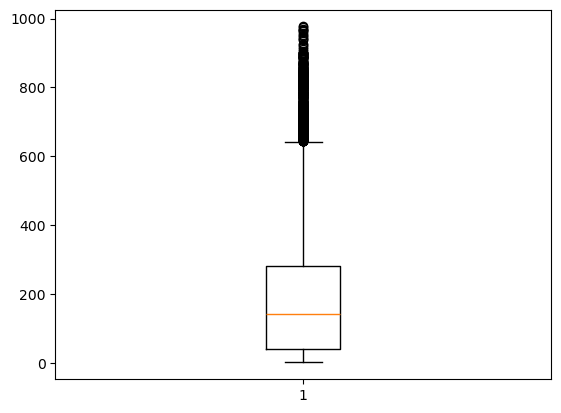

In [14]:
#Draw boxplot of cnt 
plt.boxplot(df["cnt"])
plt.show()

Given the data we have obtained, it is worth asking which season in our dataset has the highest number of rentals. 

In [15]:
# Total bike rentals by season
season_rentals = df.groupby("season")["cnt"].sum()

print(season_rentals)

season
1     471348
2     918589
3    1061129
4     841613
Name: cnt, dtype: int64


In [16]:
season_average = df.groupby("season")["cnt"].mean()
print(season_average)

season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64


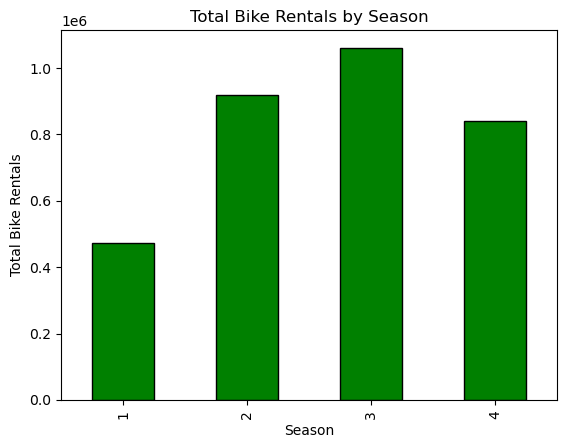

In [17]:
#Graphically representing the use of bicycles during the different seasons of the year.
season_rentals.plot(kind="bar", color="green", edgecolor="black")

plt.title("Total Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Total Bike Rentals")
plt.show()


In [18]:
# Identify the months included in season 3
season_3_months = sorted(df.loc[df["season"] == 3, "mnth"].unique())
print(season_3_months)

[6, 7, 8, 9]


In [19]:
# Total bike rentals by month during season 3
season_3_rentals = df.loc[df["season"] == 3].groupby("mnth")["cnt"].sum()
print(season_3_rentals)

mnth
6    115388
7    344948
8    351194
9    249599
Name: cnt, dtype: int64


In [20]:
# Average bike rentals by month during season 3
season_3_average = df.loc[df["season"] == 3].groupby("mnth")["cnt"].mean()
print(season_3_average)

mnth
6    240.391667
7    231.819892
8    238.097627
9    237.036087
Name: cnt, dtype: float64


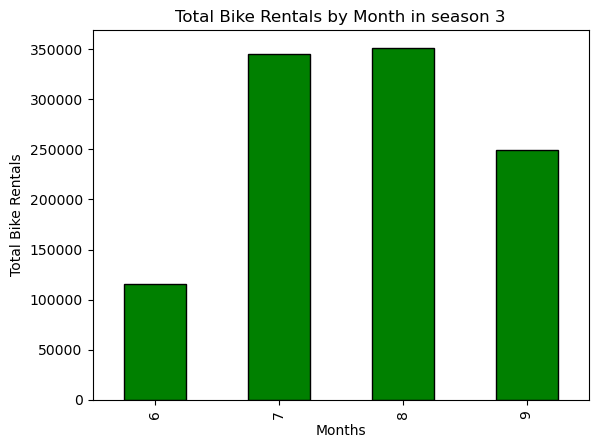

In [21]:
#Graphically representing the use of bicycles during the season 3 of the year.
season_3_rentals.plot(kind="bar", color="green", edgecolor="black")

plt.title("Total Bike Rentals by Month in season 3")
plt.xlabel("Months")
plt.ylabel("Total Bike Rentals")
plt.show()


Binomial Distribution

“What is the probability that at least 50 out of every 100 bicycle rentals selected at random during Season 3 occurred in July or August?”

In [22]:
# Filter data for season 3
season_3_data = df.loc[df["season"] == 3]

# Total rentals in July and August
summer_rentals = season_3_data.loc[
    season_3_data["mnth"].isin([7, 8]), "cnt"].sum()

# Total rentals in season 3
total_season_3_rentals = season_3_data["cnt"].sum()

# Probability of success
p = summer_rentals / total_season_3_rentals

print("Probability of success (p):", p)

Probability of success (p): 0.6560389924316459


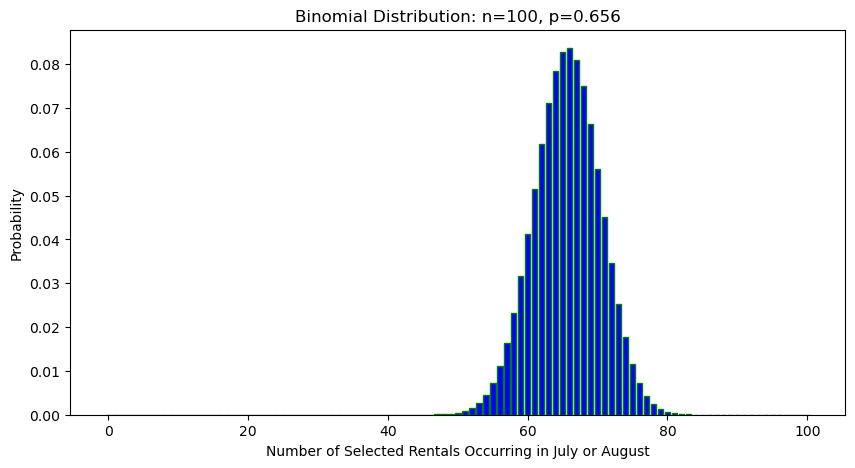

In [23]:
n= 100 #Number of randomly selected rentals 
p= 0.656 #Probability of a rental during July and August 
k= np.arange(0,n+1) 

# Binomial probability mass function (pmf)
binom_pmf= binom.pmf(k,n,p)

plt.figure(figsize=(10, 5))

#plot the binomial distribution
plt.bar(k, binom_pmf, color="blue", edgecolor="green")
plt.title("Binomial Distribution: n=100, p=0.656")
plt.xlabel("Number of Selected Rentals Occurring in July or August")
plt.ylabel("Probability")
plt.show()



Poisson Distribution

"What is the probability of having fewer than 36 bicycle rentals during a randomly selected hour between 00:00 and 06:00 in Season 3?"

In [24]:
# Filter data for Season 3
season_3_data = df.loc[df["season"] == 3]

# Calculate total rentals for each hour of the day
season_3_rentals_hours = season_3_data.groupby("hr")["cnt"].sum()

print(season_3_rentals_hours)

hr
0      13822
1       8132
2       5716
3       2930
4       1541
5       4947
6      18946
7      52000
8      79204
9      47927
10     40405
11     47319
12     56458
13     55656
14     53060
15     54221
16     69516
17    107562
18    102330
19     78383
20     58505
21     45147
22     34416
23     22986
Name: cnt, dtype: int64


In [25]:
# Filter data for Season 3
season_3_data = df.loc[df["season"] == 3]

# Calculate average rentals for each hour of the day
season_3_rentals_hours = season_3_data.groupby("hr")["cnt"].mean()

print(season_3_rentals_hours)

hr
0      73.914439
1      43.720430
2      30.731183
3      15.752688
4       8.240642
5      26.454545
6     101.315508
7     276.595745
8     421.297872
9     254.930851
10    214.920213
11    251.696809
12    300.308511
13    296.042553
14    282.234043
15    288.409574
16    369.765957
17    572.138298
18    547.219251
19    419.160428
20    312.860963
21    241.427807
22    184.042781
23    122.919786
Name: cnt, dtype: float64


In [26]:
# Filter Season 3 and hours between 00:00 and 06:00
season_3_night = season_3_data.loc[season_3_data["hr"].between(0, 6)]

# Calculate lambda
lambda_value = season_3_night["cnt"].mean()

print("Lambda:", lambda_value)

Lambda: 42.905053598774884


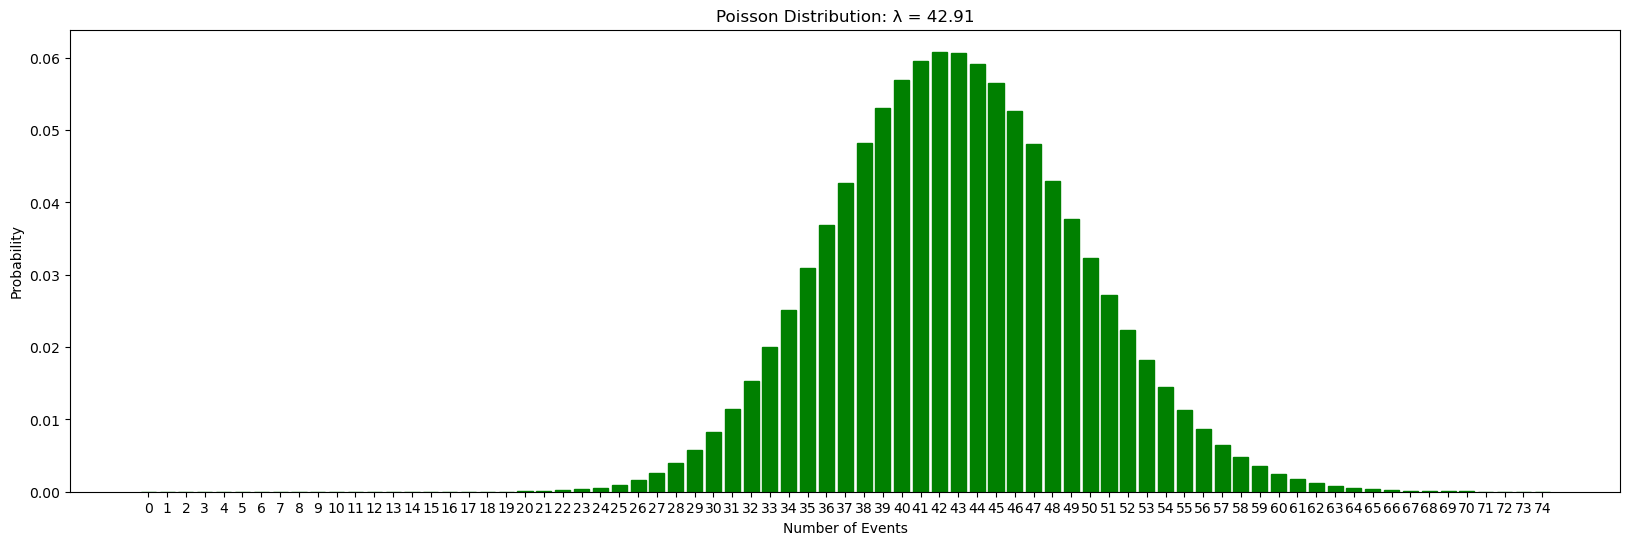

In [27]:
# Poisson 
lambda_value = 42.91  # Average number of events in the interval
k = np.arange(0, 75)  # Number of possible events (0 to 35)

# Poisson probability mass function (pmf)
poisson_pmf = poisson.pmf(k, lambda_value)
plt.figure(figsize=(20, 6))
# Plot the Poisson distribution
plt.bar(k, poisson_pmf, color='green', edgecolor='green')
plt.title('Poisson Distribution: λ = 42.91')
plt.xlabel('Number of Events')
plt.ylabel('Probability')
plt.xticks(k)
plt.show()

Normal Distribution

In [28]:
df["temp_celsius"] = df["temp"] * 41
print(df["temp_celsius"])

0         9.84
1         9.02
2         9.02
3         9.84
4         9.84
         ...  
17374    10.66
17375    10.66
17376    10.66
17377    10.66
17378    10.66
Name: temp_celsius, Length: 17379, dtype: float64


In [29]:
# Normal Distribution - Temperature

# Calculate mean and standard deviation

mean = df["temp_celsius"].mean()
std = df["temp_celsius"].std()

print("Mean Temperature:", mean)
print("Standard Deviation:", std)

Mean Temperature: 20.37647390528799
Standard Deviation: 7.894800971238327


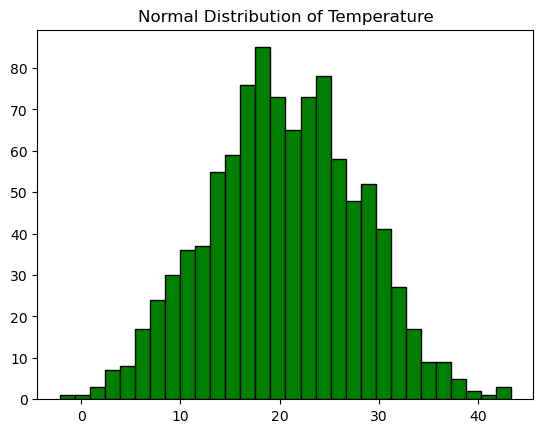

In [30]:
normal_data = np.random.normal(20.37,  7.89, 1000)

# Plot the distribution
plt.hist(normal_data, bins=30, color='green', edgecolor='black')

plt.title('Normal Distribution of Temperature')

plt.show()

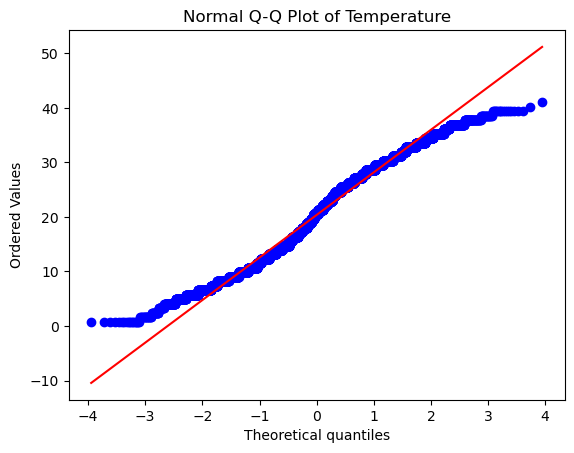

In [31]:
# Normal Q-Q Plot of Temperature

stats.probplot(df["temp_celsius"], dist="norm", plot=plt)

plt.title("Normal Q-Q Plot of Temperature")

plt.show()

In [32]:
# Empirical Rule

within_1 = ((df["temp_celsius"] >= mean - std) &
            (df["temp_celsius"] <= mean + std)).mean() * 100

within_2 = ((df["temp_celsius"] >= mean - 2*std) &
            (df["temp_celsius"] <= mean + 2*std)).mean() * 100

within_3 = ((df["temp_celsius"] >= mean - 3*std) &
            (df["temp_celsius"] <= mean + 3*std)).mean() * 100

print(within_1,within_2,within_3)

60.36020484492779 98.32556533747626 100.0
